# 🏛️ ENSIASD Taroudant — Ibn Zohr University
**Master’s in Intelligent Systems and Cyber Defense (Module M115: AI & Intelligent Systems)**  
**Instructor:** Prof. Sara EL-ATEIF | **Academic Year:** 2026–2027 | **Duration:** 2–3 Hours

---

# 🧪 Lab 2: Static Malware Detection — PE Forensics, Multi-Model Evaluation, TreeSHAP & SOC Cost Optimization

### 🎯 Lab Philosophy: Engineer a Defensible Security Decision — Don’t Just Call `.fit()`!

### 🏢 The business case: AtlasPay’s suspicious software-update incident

**AtlasPay Services is a fictional Moroccan payment-services company** operating merchant payment platforms, Windows-based back-office workstations, and point-of-sale (POS) support systems. It relies on a small internal Security Operations Center (SOC) and several third-party software vendors.

On **14 September 2026**, the SOC receives an urgent escalation: a software package distributed through a legitimate vendor-support channel has triggered endpoint security alerts at several merchant-support workstations. The package appears to be digitally signed, but its behavior and file structure are unusual. The incident is contained, but the CISO asks the security engineering team to strengthen the **pre-execution screening of Windows Portable Executable (PE) files** before new or updated software is allowed to run.

AtlasPay’s team must decide whether a machine-learning detector should:
- **Prioritize files for analyst review** when they arrive from employee endpoints, vendor portals, and support channels; or
- Eventually support **automatic quarantine/blocking**, where a false alarm could interrupt legitimate payment-support operations.

The SOC has **6 analysts**, handles approximately **12,000 PE-file submissions per day**, and wants to keep the first-stage model-generated queue below **120 alerts per day**. For the initial deployment, the model is a **decision-support control**: it recommends suspicious files for review; it does not independently declare a file malicious or automatically block business-critical software.

> **Important source boundary:** AtlasPay, the incident, the operating figures, and the cost assumptions are fictional teaching scenario details. The notebook uses a deterministic **EMBER-inspired synthetic dataset** of 6,000 PE-file records; it is not AtlasPay telemetry, not the real EMBER benchmark, and not evidence of production detection performance. Your task is to determine what can and cannot be concluded from this experiment.

### 🧠 Your engineering mission

You are the applied ML team asked to deliver a defensible recommendation to AtlasPay’s CISO. You must investigate the data, design the evaluation, compare model families, examine errors, and select a model and operating threshold under explicit operational constraints.

You will complete **5 engineering phases**:

1. **Phase 1 — Forensic Data Understanding & Trap Detection:** Audit class balance, missing values, duplicate records, uninformative identifiers, post-scan target leakage, corrupted parser values, and feature relationships before training.
2. **Phase 2 — Leakage-Free Preprocessing & 5-Fold Cross-Validation:** Build fold-safe `sklearn.pipeline.Pipeline` objects and evaluate candidates using `StratifiedKFold(n_splits=5)`.
3. **Phase 3 — Multi-Algorithm Head-to-Head Benchmark:** Compare a linear baseline (`LogisticRegression`), a single decision tree, a bagging ensemble (`RandomForestClassifier`), a boosting model (`LightGBM` when installed, otherwise accurately named `HistGradientBoostingClassifier`), and—where provided—a heterogeneous stacking model.
4. **Phase 4 — Error Forensics & TreeSHAP Explainability:** Investigate verified model disagreements and use global and local SHAP explanations to understand what the selected tree model learned. SHAP explains model behavior; it does not prove causality or establish that a file is malware.
5. **Phase 5 — SOC Cost Matrix & Threshold Optimization:** Select thresholds using development data only, freeze the decision rule, and evaluate it once on the lockbox test set. Compare analyst-assisted triage with the higher-risk automatic-blocking scenario.

### 📌 What you must deliver

- A completed notebook with reproducible code and outputs.
- A model-comparison table and a reasoned shortlist.
- A verified error-forensics example and a SHAP interpretation.
- A threshold/cost analysis that respects the lockbox test protocol.
- A concise **CISO recommendation**: model, threshold, deployment mode, operating constraints, and pre-production safeguards.

**Core question:** *Which model should AtlasPay deploy first, for which operational role, and what evidence would justify trusting it?*

## Phase 0 — Environment and dataset
Run the setup and dataset-generation cells. Do not modify the random seed if you want results to be comparable with the instructor solution.

In [53]:
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve)
from sklearn.base import clone
SEED = 42
rng = np.random.default_rng(SEED)

In [54]:
def load_ember_forensic_dataset(n_samples=6000, seed=42):
    rng = np.random.default_rng(seed)
    y = rng.binomial(1, 0.25, n_samples)
    is_mal = y == 1
    archetype_b = is_mal & (rng.random(n_samples) < 0.35)
    archetype_a = is_mal & (~archetype_b)

    max_entropy = np.where(archetype_a, rng.normal(7.35, .40, n_samples),
                  np.where(archetype_b, rng.normal(4.30, .55, n_samples),
                           rng.normal(5.50, .95, n_samples))).clip(1, 7.99)
    import_count = np.where(archetype_a, rng.normal(14, 7, n_samples),
                   np.where(archetype_b, rng.normal(115, 35, n_samples),
                            rng.normal(95, 45, n_samples))).clip(0, 500).astype(float)
    suspicious_apis = np.where(archetype_a, rng.poisson(3.0, n_samples),
                      np.where(archetype_b, rng.poisson(11.5, n_samples),
                               rng.poisson(1.8, n_samples)))
    has_valid_sig = np.where(archetype_a, rng.binomial(1,.03,n_samples),
                    np.where(archetype_b, rng.binomial(1,.55,n_samples),
                             rng.binomial(1,.78,n_samples)))
    has_rwx = np.where(is_mal, rng.binomial(1,.52,n_samples), rng.binomial(1,.04,n_samples))
    vsize = np.where(archetype_a, rng.uniform(1.8,6.5,n_samples),
                     rng.normal(1.08,.22,n_samples)).clip(.2,15)
    res_entropy = np.where(is_mal, rng.normal(6.2,1.3,n_samples),
                           rng.normal(4.0,1.2,n_samples)).clip(0,7.99)
    urls = np.where(is_mal, rng.poisson(4.2,n_samples), rng.poisson(.6,n_samples))
    bad_time = np.where(is_mal, rng.binomial(1,.38,n_samples), rng.binomial(1,.03,n_samples))
    sections = np.where(is_mal, rng.integers(1,11,n_samples), rng.integers(3,7,n_samples))
    tls = np.where(is_mal, rng.binomial(1,.26,n_samples), rng.binomial(1,.02,n_samples))
    exports = np.where(is_mal, rng.poisson(1.0,n_samples), rng.poisson(7.5,n_samples))
    flip = rng.random(n_samples) < .04
    y_final = np.where(flip, 1-y, y)
    vt = np.where(y_final==1, rng.integers(18,68,n_samples), rng.integers(0,3,n_samples))
    df = pd.DataFrame({
      "SHA256_File_ID":[f"sha256_{i:05d}_pe" for i in range(n_samples)],
      "Max_Section_Entropy":max_entropy, "Import_Count":import_count,
      "Suspicious_API_Imports":suspicious_apis, "Has_Valid_Signature":has_valid_sig,
      "Has_RWX_Section":has_rwx, "Virtual_to_Raw_Size_Ratio":vsize,
      "Resource_Entropy":res_entropy, "Num_Embedded_URLs_IPs":urls,
      "Abnormal_Compile_Timestamp":bad_time, "Num_Sections":sections,
      "Has_TLS_Callback":tls, "Export_Count":exports,
      "VT_PostScan_Detections":vt, "Is_Malware":y_final
    })
    df.loc[rng.random(n_samples)<.05, "Resource_Entropy"] = np.nan
    df.loc[rng.random(n_samples)<.04, "Import_Count"] = np.nan
    df.loc[rng.random(n_samples)<.01, "Virtual_to_Raw_Size_Ratio"] = 99999.0
    return df
df_pe = load_ember_forensic_dataset()
print(df_pe.shape, "Malware prevalence:", round(df_pe.Is_Malware.mean(),3))
display(df_pe.head())

(6000, 15) Malware prevalence: 0.268


,SHA256_File_ID,Max_Section_Entropy,Import_Count,Suspicious_API_Imports,Has_Valid_Signature,Has_RWX_Section,Virtual_to_Raw_Size_Ratio,Resource_Entropy,Num_Embedded_URLs_IPs,Abnormal_Compile_Timestamp,Num_Sections,Has_TLS_Callback,Export_Count,VT_PostScan_Detections,Is_Malware
0,sha256_00000_pe,7.461459,25.464072,2,0,1,5.158277,7.081268,3,0,2,0,2,45,1
1,sha256_00001_pe,5.872605,104.603878,2,1,0,0.871620,4.123092,0,0,4,0,6,2,0
2,sha256_00002_pe,7.188000,13.758941,4,0,1,3.447490,4.776004,2,0,9,0,2,36,1
3,sha256_00003_pe,6.330688,96.169063,2,1,0,1.027833,4.654296,3,0,4,0,8,0,0
4,sha256_00004_pe,5.211025,97.108682,3,0,0,1.031020,4.442302,0,0,5,0,2,1,0


## Phase 1 — Forensic Data Understanding & Trap Detection

The target is `Is_Malware` (`1 = malware`, `0 = benign`). At deployment time, the detector must only use information available when the PE file is first inspected.

### Tasks
1. Report dataset dimensions, class balance, missing values, duplicates and summary statistics.
2. Identify the identifier and the post-scan field. Explain why each should be excluded.
3. Investigate `Virtual_to_Raw_Size_Ratio`: identify the suspicious parser value `99999.0`. Decide how to handle it and justify your choice.
4. Visualize at least two feature relationships with the target. Discuss whether a single linear boundary is likely to capture all patterns.
5. Define the prediction task, positive class, and the operational meaning of FP and FN.

**Do not** use `VT_PostScan_Detections` as an input feature. It is recorded after the event and would cause target leakage.

In [55]:
# TASK 1: audit data quality.
# TODO: missing counts, duplicates, class balance, describe()


print("Dataset shape:", df_pe.shape)

print("\nMissing values per column:")
display(df_pe.isna().sum())

print("\nDuplicate rows:")
print(df_pe.duplicated().sum())

print("\nClass counts (Is_Malware):")
display(df_pe["Is_Malware"].value_counts().rename(
    index={0: "Not malware", 1: "Malware"}
))

print("\nClass proportions:")
display(df_pe["Is_Malware"].value_counts(normalize=True).rename(
    index={0: "Not malware", 1: "Malware"}
).round(3))

print("\nDescriptive statistics:")
display(df_pe.describe(include="all").T)

Dataset shape: (6000, 15)

Missing values per column:


SHA256_File_ID                  0
Max_Section_Entropy             0
Import_Count                  229
Suspicious_API_Imports          0
Has_Valid_Signature             0
Has_RWX_Section                 0
Virtual_to_Raw_Size_Ratio       0
Resource_Entropy              289
Num_Embedded_URLs_IPs           0
Abnormal_Compile_Timestamp      0
Num_Sections                    0
Has_TLS_Callback                0
Export_Count                    0
VT_PostScan_Detections          0
Is_Malware                      0
dtype: int64


Duplicate rows:
0

Class counts (Is_Malware):


Is_Malware
Not malware    4389
Malware        1611
Name: count, dtype: int64


Class proportions:


Is_Malware
Not malware    0.732
Malware        0.268
Name: proportion, dtype: float64


Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
SHA256_File_ID,6000,6000,sha256_00000_pe,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Max_Section_Entropy,6000.0,NaN,NaN,NaN,5.70901,1.170152,2.146111,4.821742,5.639862,6.604762,7.99
Import_Count,5771.0,NaN,NaN,NaN,83.386866,50.30113,0.0,41.184528,85.663796,120.408591,320.325585
Suspicious_API_Imports,6000.0,NaN,NaN,NaN,2.800167,3.09443,0.0,1.0,2.0,3.0,24.0
Has_Valid_Signature,6000.0,NaN,NaN,NaN,0.630833,0.482619,0.0,0.0,1.0,1.0,1.0
Has_RWX_Section,6000.0,NaN,NaN,NaN,0.149833,0.356938,0.0,0.0,0.0,0.0,1.0
Virtual_to_Raw_Size_Ratio,6000.0,NaN,NaN,NaN,984.890348,9868.008483,0.367195,0.95557,1.129836,1.366755,99999.0
Resource_Entropy,5711.0,NaN,NaN,NaN,4.53516,1.501097,0.0,3.483114,4.432941,5.517712,7.99
Num_Embedded_URLs_IPs,6000.0,NaN,NaN,NaN,1.468333,1.951742,0.0,0.0,1.0,2.0,11.0
Abnormal_Compile_Timestamp,6000.0,NaN,NaN,NaN,0.114833,0.318847,0.0,0.0,0.0,0.0,1.0


Rows with 99999.0: 59


,SHA256_File_ID,Virtual_to_Raw_Size_Ratio,Is_Malware
332,sha256_00332_pe,99999.0,0
400,sha256_00400_pe,99999.0,0
408,sha256_00408_pe,99999.0,0
461,sha256_00461_pe,99999.0,0
477,sha256_00477_pe,99999.0,0


Ratio summary excluding the suspicious value:


count    5941.000000
mean        1.582408
std         1.298046
min         0.367195
25%         0.953186
50%         1.126470
75%         1.355024
max         6.497630
Name: Virtual_to_Raw_Size_Ratio, dtype: float64

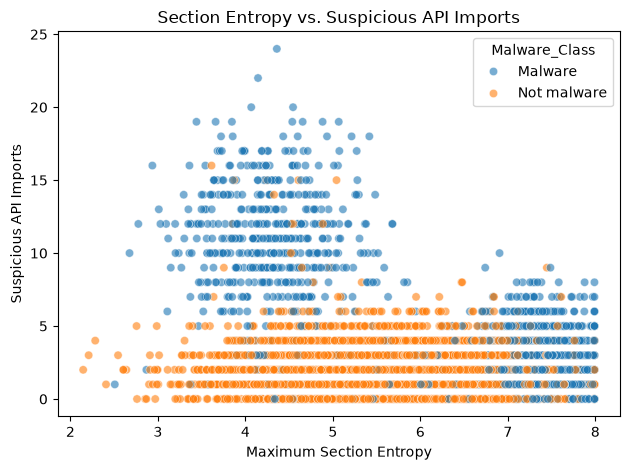

In [56]:
# TASK 2: inspect the suspicious ratio values and feature distributions.
# TODO: count 99999.0 values; visualize Max_Section_Entropy vs Suspicious_API_Imports,
# using Is_Malware as the hue.

import matplotlib.pyplot as plt
import seaborn as sns

# Count and inspect the suspicious parser value
ratio_col = "Virtual_to_Raw_Size_Ratio"
sentinel_value = 99999.0
sentinel_mask = df_pe[ratio_col].eq(sentinel_value)

print(f"Rows with {sentinel_value}: {sentinel_mask.sum()}")
display(df_pe.loc[sentinel_mask, ["SHA256_File_ID", ratio_col, "Is_Malware"]].head())

# Summarize plausible ratio values without the sentinel
print("Ratio summary excluding the suspicious value:")
display(df_pe.loc[~sentinel_mask, ratio_col].describe())

# Make the target labels easier to read in the plot
plot_data = df_pe.assign(
    Malware_Class=df_pe["Is_Malware"].map({0: "Not malware", 1: "Malware"})
)

# Compare two features, colored by target class
sns.scatterplot(
    data=plot_data,
    x="Max_Section_Entropy",
    y="Suspicious_API_Imports",
    hue="Malware_Class",
    alpha=0.6
)

plt.title("Section Entropy vs. Suspicious API Imports")
plt.xlabel("Maximum Section Entropy")
plt.ylabel("Suspicious API Imports")
plt.tight_layout()
plt.show()


In [57]:
# TASK 3: define the target and clean feature matrix.
# TODO: drop SHA256_File_ID, VT_PostScan_Detections and Is_Malware from X.
# TODO: replace impossible Virtual_to_Raw_Size_Ratio == 99999.0 with np.nan.
# Keep the target y separate.

import numpy as np

# Keep the prediction target separate
y = df_pe["Is_Malware"].copy()

# Create features without the identifier, post-scan field, or target
X = df_pe.drop(
    columns=["SHA256_File_ID", "VT_PostScan_Detections", "Is_Malware"]
).copy()

# Replace the impossible parser value with a missing value
X["Virtual_to_Raw_Size_Ratio"] = X["Virtual_to_Raw_Size_Ratio"].replace(99999.0, np.nan)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Missing values in Virtual_to_Raw_Size_Ratio:",
      X["Virtual_to_Raw_Size_Ratio"].isna().sum())

Feature matrix shape: (6000, 12)
Target shape: (6000,)
Missing values in Virtual_to_Raw_Size_Ratio: 59


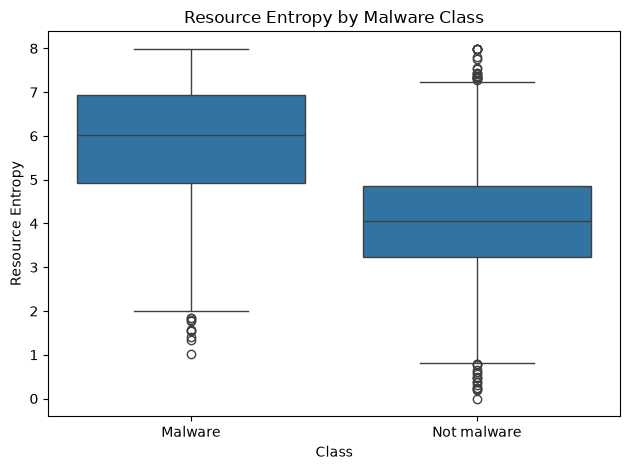

In [58]:
# Phase 1, Task 4: a second feature relationship with the target
sns.boxplot(
    data=plot_data,
    x="Malware_Class",
    y="Resource_Entropy"
)
plt.title("Resource Entropy by Malware Class")
plt.xlabel("Class")
plt.ylabel("Resource Entropy")
plt.tight_layout()
plt.show()

### Phase 1 findings

- **Data audit (Task 1):** The synthetic dataset has 6,000 rows and 15 columns. It contains 4,389 benign files (73.2%) and 1,611 malware files (26.8%), with no duplicate rows. `Import_Count` has 229 missing values and `Resource_Entropy` has 289 missing values. The descriptive-statistics table above summarizes the columns.
- **Excluded columns (Task 2):** `SHA256_File_ID` identifies a file but is not a behavioral measurement, so it is excluded from model inputs. `VT_PostScan_Detections` is known only after scanning and may leak information about the label, so it is also excluded.
- **Parser value (Task 3):** There are 59 rows with `Virtual_to_Raw_Size_Ratio == 99999.0`. This is an implausible parser placeholder, so the feature-matrix code changes it to `NaN` rather than treating it as a valid ratio or deleting those rows.
- **Feature relationships (Task 4):** The scatterplot and boxplot above compare features with the malware class. The patterns include different feature combinations and class overlap, so a single linear decision boundary may not capture every pattern.
- **Prediction and errors (Task 5):** Predict whether a PE file is malware before it executes. The positive class is `Is_Malware = 1`. A false positive is a benign file flagged for review; a false negative is a malicious file that is not flagged.

## Phase 2 — Leakage-Free Preprocessing & 5-Fold Cross-Validation

Use a stratified 80/20 development/test split. The test set is a lockbox and must not be used for model selection or threshold tuning.

Within the development set, compare models using 5-fold stratified cross-validation. All learned preprocessing (imputation and scaling) must be inside each pipeline so it is refitted separately in each training fold.

### Tasks
1. Create `X_dev`, `X_test`, `y_dev`, `y_test` using a stratified split.
2. Define preprocessing pipelines with median imputation inside each pipeline. Use `RobustScaler` for Logistic Regression; explain why scaling is generally unnecessary for tree models.

The next phase uses the development set and five stratified folds to compare models. Keep the lockbox test set unused during model selection.

In [59]:
# Phase 2, Task 1: make one stratified split and keep the test set locked.
X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

print("Development shape:", X_dev.shape)
print("Test shape:", X_test.shape)
print("Development malware prevalence:", round(y_dev.mean(), 3))
print("Test malware prevalence:", round(y_test.mean(), 3))

# Median imputation and scaling are fitted inside each CV fold.
# Scaling is used for Logistic Regression because it is distance/optimization-sensitive;
# tree splits depend on feature ordering, so scaling is generally unnecessary for trees.
logistic_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler()),
    ("model", LogisticRegression(max_iter=2000, random_state=SEED))
])

Development shape: (4800, 12)
Test shape: (1200, 12)
Development malware prevalence: 0.269
Test malware prevalence: 0.268


## Phase 3 — Multi-Algorithm Head-to-Head Benchmark

### Tasks
1. Build candidate pipelines: Logistic Regression (linear baseline), Deep Decision Tree, Random Forest, and LightGBM when available; otherwise use and accurately label `HistGradientBoostingClassifier`.
2. Evaluate all candidates using the same five stratified folds. Report mean train F1, validation F1, PR-AUC, and fit time.
3. Interpret bias and variance, compare model families, and select candidates for further investigation using the Decision Checkpoint below.

In [60]:
# Phase 3: compare candidate models on identical stratified folds.
import importlib.util
from sklearn.ensemble import HistGradientBoostingClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

candidate_models = {
    "Logistic Regression": logistic_pipeline,
    "Deep Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(random_state=SEED))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=200, random_state=SEED, n_jobs=-1
        ))
    ])
}

if importlib.util.find_spec("lightgbm") is not None:
    from lightgbm import LGBMClassifier
    candidate_models["LightGBM"] = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", LGBMClassifier(
            n_estimators=200, random_state=SEED, n_jobs=-1, verbosity=-1
        ))
    ])
else:
    candidate_models["Histogram Gradient Boosting"] = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", HistGradientBoostingClassifier(
            max_iter=150, learning_rate=0.08, random_state=SEED
        ))
    ])

scoring = {"f1": "f1", "pr_auc": "average_precision"}
cv_results = {}
summary_rows = []

for name, pipeline in candidate_models.items():
    scores = cross_validate(
        pipeline,
        X_dev,
        y_dev,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=1,
        error_score="raise"
    )
    cv_results[name] = scores
    summary_rows.append({
        "model": name,
        "mean_train_f1": scores["train_f1"].mean(),
        "mean_validation_f1": scores["test_f1"].mean(),
        "mean_validation_pr_auc": scores["test_pr_auc"].mean(),
        "mean_fit_time_seconds": scores["fit_time"].mean()
    })

phase2_results = pd.DataFrame(summary_rows).sort_values(
    "mean_validation_pr_auc", ascending=False
).reset_index(drop=True)
display(phase2_results.round(3))

,model,mean_train_f1,mean_validation_f1,mean_validation_pr_auc,mean_fit_time_seconds
0,Logistic Regression,0.923,0.924,0.908,0.016
1,Random Forest,1.000,0.924,0.905,0.332
2,Histogram Gradient Boosting,0.989,0.922,0.905,0.267
3,Deep Decision Tree,1.000,0.830,0.733,0.024


### Decision checkpoint 1 — Select a shortlist

**1. Which model shows the largest train–validation gap? What does it suggest?**

The Deep Decision Tree has the largest F1 gap: about 1.000 train F1 versus 0.830 validation F1 (gap ≈ 0.170). This suggests overfitting.

**2. Does the linear baseline already perform competitively?**

Yes. Logistic Regression is competitive, with validation F1 ≈ 0.924 and the best validation PR-AUC ≈ 0.908. Its mean fit time is also the shortest (≈ 0.018 seconds per fold in this run).

**3. Does Random Forest improve on the single tree?**

Yes. Random Forest improves validation F1 from ≈ 0.830 to ≈ 0.924 and PR-AUC from ≈ 0.733 to ≈ 0.905 compared with the Deep Decision Tree. Its train F1 is 1.000, so it still has a train–validation gap.

**4. Does boosting improve PR-AUC enough to justify its complexity?**

No meaningful improvement is shown in this run. Histogram Gradient Boosting (used because LightGBM is not installed) has validation PR-AUC ≈ 0.905 versus ≈ 0.908 for Logistic Regression.

**5. Is stacking justified by the measured gain, runtime and deployment context?**

There is no measured gain to justify stacking because it was not evaluated in this benchmark. Given the similar scores and the need to consider runtime and operational simplicity, do not assume stacking is better. Shortlist Logistic Regression and Random Forest for further investigation; this is a development-set decision, not a final deployment decision.

**AtlasPay operating constraint:** the service receives about 12,000 PE files/day, while the 6-person SOC wants no more than 120 model-generated review alerts/day. Treat this as a queue-capacity constraint to test—not as a result guaranteed by the synthetic dataset. Training time matters during model updates; inference latency matters during scanning. These are separate measurements. The local inference timing above is hardware/runtime-dependent and does not establish that the 120-alert/day limit is met.

In [61]:
# Phase 3: time inference for the two best benchmark candidates.
# This uses development rows only; it does not inspect test labels.
import time

shortlist = phase2_results["model"].head(2).tolist()
latency_rows = []
latency_batch = X_dev.iloc[:min(1000, len(X_dev))]
repeats = 30

for name in shortlist:
    fitted_model = clone(candidate_models[name]).fit(X_dev, y_dev)
    fitted_model.predict_proba(latency_batch.iloc[:1])
    start = time.perf_counter()
    for _ in range(repeats):
        fitted_model.predict_proba(latency_batch)
    elapsed = time.perf_counter() - start
    latency_rows.append({
        "model": name,
        "batch_size": len(latency_batch),
        "milliseconds_per_1000_files": elapsed / repeats * 1000 / len(latency_batch) * 1000
    })

latency_results = pd.DataFrame(latency_rows)
display(latency_results.round(2))
print("Latency is a local benchmark; timings depend on this machine and runtime.")

,model,batch_size,milliseconds_per_1000_files
0,Logistic Regression,1000,1.16
1,Random Forest,1000,37.47


Latency is a local benchmark; timings depend on this machine and runtime.


## Phase 4 — Error Forensics & TreeSHAP Explainability

Choose a held-out test observation for which the candidate models disagree. Do not hard-code a story before verifying the predictions.

### Tasks
1. Generate probabilities for the same test observations from Logistic Regression and your selected tree ensemble.
2. Find a malware observation where Logistic Regression predicts benign at the chosen illustrative threshold while the tree model predicts malware. If no such observation exists, report that honestly and choose another meaningful disagreement.
3. Print the ground-truth label, feature values, probabilities and predictions.
4. Build global and local SHAP explanations for a supported tree model.
5. Interpret a beeswarm and a local waterfall. Explain why SHAP is not causal evidence.

In [62]:
# Phase 4, Tasks 1-3: fit on development data and inspect the lockbox test set.
# The 0.50 threshold is only for this disagreement example, not threshold tuning.
from sklearn.base import clone

models_for_forensics = {
    "Logistic Regression": clone(candidate_models["Logistic Regression"]),
    "Random Forest": clone(candidate_models["Random Forest"])
}
for model in models_for_forensics.values():
    model.fit(X_dev, y_dev)

lr_probability = models_for_forensics["Logistic Regression"].predict_proba(X_test)[:, 1]
rf_probability = models_for_forensics["Random Forest"].predict_proba(X_test)[:, 1]
lr_prediction = (lr_probability >= 0.50).astype(int)
rf_prediction = (rf_probability >= 0.50).astype(int)
y_test_array = y_test.to_numpy()

# Prefer the requested case: true malware, LR says benign, RF says malware.
requested_case = np.flatnonzero(
    (y_test_array == 1) & (lr_prediction == 0) & (rf_prediction == 1)
)
if len(requested_case):
    case_position = int(requested_case[0])
    case_reason = "malware: Logistic Regression predicts benign; Random Forest predicts malware"
else:
    disagreement = np.flatnonzero(lr_prediction != rf_prediction)
    if len(disagreement):
        case_position = int(disagreement[0])
        case_reason = "alternate verified model-prediction disagreement (requested pattern not found)"
    else:
        case_position = int(np.argmax(np.abs(lr_probability - rf_probability)))
        case_reason = "no different 0.50 predictions; showing the largest probability difference instead"

case_index = X_test.index[case_position]
case_truth = int(y_test_array[case_position])
case_lr_prediction = int(lr_prediction[case_position])
case_rf_prediction = int(rf_prediction[case_position])
case_features = X_test.iloc[[case_position]]

print("Verified diagnostic case:", case_reason)
print("Test-row index:", case_index)
print("Ground truth:", "Malware" if case_truth == 1 else "Benign")
print(f"Logistic Regression: P(malware)={lr_probability[case_position]:.3f}, prediction={case_lr_prediction}")
print(f"Random Forest:       P(malware)={rf_probability[case_position]:.3f}, prediction={case_rf_prediction}")
print("Features for this test row:")
display(case_features.T.rename(columns={case_features.index[0]: "value"}))

if case_lr_prediction != case_truth:
    print("Logistic Regression is incorrect on this row.")
if case_rf_prediction != case_truth:
    print("Random Forest is incorrect on this row.")
if case_lr_prediction == case_truth and case_rf_prediction == case_truth:
    print("Both models are correct on this row; this is a disagreement in confidence/pattern, not an error.")

Verified diagnostic case: malware: Logistic Regression predicts benign; Random Forest predicts malware
Test-row index: 5787
Ground truth: Malware
Logistic Regression: P(malware)=0.304, prediction=0
Random Forest:       P(malware)=0.610, prediction=1
Features for this test row:


,value
Max_Section_Entropy,4.603163
Import_Count,116.690922
Suspicious_API_Imports,3.000000
Has_Valid_Signature,0.000000
Has_RWX_Section,0.000000
Virtual_to_Raw_Size_Ratio,0.944756
Resource_Entropy,NaN
Num_Embedded_URLs_IPs,2.000000
Abnormal_Compile_Timestamp,0.000000
Num_Sections,9.000000


Logistic Regression is incorrect on this row.


Global explanation: each point is one test file; color indicates the feature value.


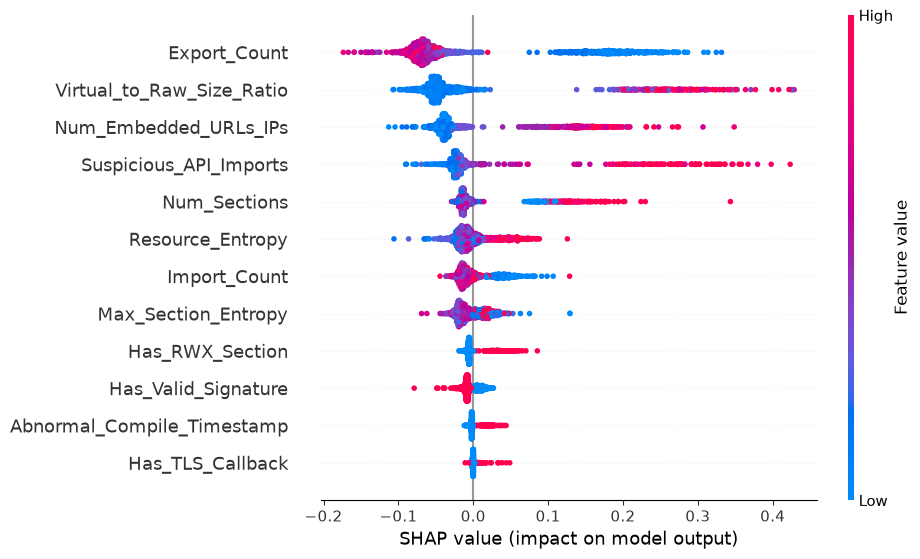

Local explanation for the verified diagnostic row:


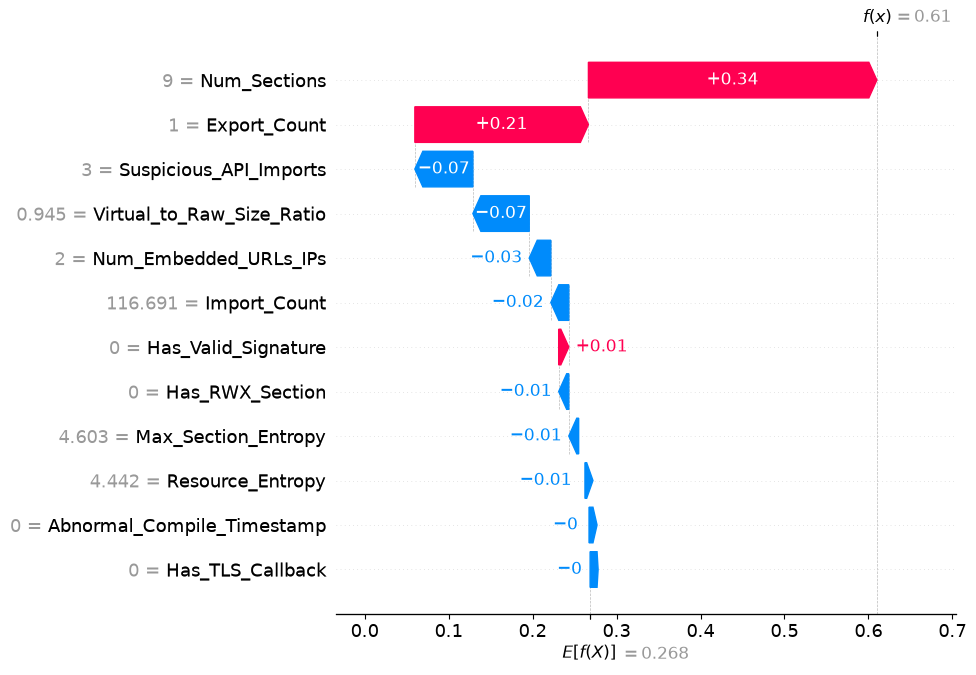

In [63]:
# Phase 4, Tasks 4-5: explain the fitted Random Forest with TreeSHAP.
import shap

rf_pipeline = models_for_forensics["Random Forest"]
rf_estimator = rf_pipeline.named_steps["model"]
imputer = rf_pipeline.named_steps["imputer"]
X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

tree_explainer = shap.TreeExplainer(rf_estimator)
all_shap_explanations = tree_explainer(X_test_imputed)
if all_shap_explanations.values.ndim == 3:
    malware_explanation = shap.Explanation(
        values=all_shap_explanations.values[:, :, 1],
        base_values=all_shap_explanations.base_values[:, 1],
        data=all_shap_explanations.data,
        feature_names=list(X_test.columns)
    )
else:
    malware_explanation = all_shap_explanations

print("Global explanation: each point is one test file; color indicates the feature value.")
shap.plots.beeswarm(malware_explanation, max_display=12)

print("Local explanation for the verified diagnostic row:")
shap.plots.waterfall(malware_explanation[case_position], max_display=12)

## Phase 5 — SOC Cost Matrix & Threshold Optimization

For the AtlasPay teaching scenario, the SOC supplies these *illustrative planning assumptions* (not measured company costs):

- False positive (FP): $25 per alert (analyst investigation and workflow friction).
- False negative (FN): $500 per missed malicious file (expected response/remediation cost).
- A future inline-blocking scenario may raise FP cost to $2,000 because blocking a legitimate vendor update or payment-support executable could interrupt operations.

\[
C(\tau)=25\,FP(\tau)+500\,FN(\tau)
\]

### Critical protocol
Select the threshold using development data only (for example, out-of-fold development predictions). Freeze the selected threshold. Evaluate it once on the lockbox test set. Never search test thresholds and report the minimum as final performance.

### Tasks
1. Generate out-of-fold probabilities for each shortlisted model on the development set.
2. Find the cost-minimizing threshold on those OOF predictions.
3. Freeze the threshold and evaluate FP, FN, precision, recall and cost on the test set.
4. Repeat threshold selection under `C_FP = $2,000` using development predictions. Explain why the preferred threshold changes.
5. Discuss the limitations of the cost assumptions and whether the dataset prevalence represents the intended deployment environment.

**Capacity check:** Compare the number of test-set alerts at your frozen threshold with the scenario’s 120-alert/day target only as an indicative exercise. The test set is a sample, the dataset prevalence is synthetic, and a simple test-set count must not be presented as a validated daily alert forecast. Explain what real telemetry and calibration would be required.

In [64]:
# Phase 5: choose thresholds from development out-of-fold predictions only.
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, precision_score, recall_score

COST_FP = 25
COST_FN = 500
INLINE_BLOCK_COST_FP = 2000

def cost_threshold_search(y_true, probabilities, cost_fp, cost_fn):
    """Return the minimum-cost threshold over all distinct OOF score decisions."""
    y_array = np.asarray(y_true, dtype=int)
    probabilities = np.asarray(probabilities, dtype=float)
    thresholds = np.r_[0.0, np.unique(probabilities), np.nextafter(1.0, np.inf)]
    rows = []
    for threshold in thresholds:
        prediction = (probabilities >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_array, prediction, labels=[0, 1]).ravel()
        rows.append({
            "threshold": threshold,
            "fp": fp,
            "fn": fn,
            "precision": precision_score(y_array, prediction, zero_division=0),
            "recall": recall_score(y_array, prediction, zero_division=0),
            "cost": cost_fp * fp + cost_fn * fn
        })
    return min(rows, key=lambda row: (row["cost"], -row["threshold"]))

oof_probabilities = {}
threshold_selections = {}
for name in shortlist:
    oof_probability = cross_val_predict(
        clone(candidate_models[name]),
        X_dev,
        y_dev,
        cv=cv,
        method="predict_proba",
        n_jobs=1
    )[:, 1]
    oof_probabilities[name] = oof_probability
    threshold_selections[name] = {
        "analyst_review": cost_threshold_search(y_dev, oof_probability, COST_FP, COST_FN),
        "inline_blocking": cost_threshold_search(y_dev, oof_probability, INLINE_BLOCK_COST_FP, COST_FN)
    }

# Fit each shortlisted model on all development rows and evaluate once per frozen OOF threshold.
test_evaluation_rows = []
fitted_shortlist = {}
for name in shortlist:
    fitted_model = clone(candidate_models[name]).fit(X_dev, y_dev)
    fitted_shortlist[name] = fitted_model
    test_probability = fitted_model.predict_proba(X_test)[:, 1]
    for scenario, fp_cost in [("analyst_review", COST_FP), ("inline_blocking", INLINE_BLOCK_COST_FP)]:
        selected = threshold_selections[name][scenario]
        prediction = (test_probability >= selected["threshold"]).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, prediction, labels=[0, 1]).ravel()
        test_evaluation_rows.append({
            "model": name,
            "scenario": scenario,
            "OOF_selected_threshold": selected["threshold"],
            "test_TP": tp,
            "test_FP": fp,
            "test_FN": fn,
            "test_TN": tn,
            "test_precision": precision_score(y_test, prediction, zero_division=0),
            "test_recall": recall_score(y_test, prediction, zero_division=0),
            "test_cost": fp_cost * fp + COST_FN * fn,
            "test_alerts": int(prediction.sum()),
            "indicative_alerts_per_12000": int(prediction.sum()) / len(y_test) * 12000
        })

oof_threshold_rows = []
for name, scenarios in threshold_selections.items():
    for scenario, selected in scenarios.items():
        oof_threshold_rows.append({"model": name, "scenario": scenario, **selected})

oof_threshold_results = pd.DataFrame(oof_threshold_rows)
test_cost_results = pd.DataFrame(test_evaluation_rows)
print("OOF threshold selection (development data only):")
display(oof_threshold_results.round(3))
print("One-time lockbox test evaluation at the frozen OOF thresholds:")
display(test_cost_results.round(3))
print("The scaled alert figure is only an indicative sample-rate calculation, not a daily forecast.")

OOF threshold selection (development data only):


,model,scenario,threshold,fp,fn,precision,recall,cost
0,Logistic Regression,analyst_review,0.287,49,142,0.959,0.890,72225
1,Logistic Regression,inline_blocking,0.502,39,149,0.967,0.884,152500
2,Random Forest,analyst_review,0.350,51,143,0.957,0.889,72775
3,Random Forest,inline_blocking,0.700,39,149,0.967,0.884,152500


One-time lockbox test evaluation at the frozen OOF thresholds:


,model,scenario,OOF_selected_threshold,test_TP,test_FP,test_FN,test_TN,test_precision,test_recall,test_cost,test_alerts,indicative_alerts_per_12000
0,Logistic Regression,analyst_review,0.287,288,10,34,868,0.966,0.894,17250,298,2980.0
1,Logistic Regression,inline_blocking,0.502,286,8,36,870,0.973,0.888,34000,294,2940.0
2,Random Forest,analyst_review,0.350,288,10,34,868,0.966,0.894,17250,298,2980.0
3,Random Forest,inline_blocking,0.700,282,8,40,870,0.972,0.876,36000,290,2900.0


The scaled alert figure is only an indicative sample-rate calculation, not a daily forecast.


### Phase 5 explanation and interpretation

The threshold is the probability cutoff for flagging a file as malware. The code creates out-of-fold (OOF) probabilities on the development data, tests candidate cutoffs there, and chooses the cutoff with the lowest assumed cost. The test set is not used to select the cutoff; it is evaluated after the OOF threshold is frozen.

For analyst review, the minimum-OOF-cost thresholds are about **0.287 for Logistic Regression** and **0.350 for Random Forest**. At the selected thresholds, Logistic Regression has OOF cost $72,225 (49 FP, 142 FN), and Random Forest has $72,775 (51 FP, 143 FN). On the lockbox test set, both produce 10 FP and 34 FN, for cost **$17,250**, precision about **96.6%**, and recall about **89.4%**.

When the assumed FP cost rises from $25 to $2,000 for inline blocking, the cost-minimizing thresholds rise to about **0.502 for Logistic Regression** and **0.700 for Random Forest**. A higher cutoff makes the model flag fewer files, reducing costly false alarms but allowing more malware to be missed. On test, Logistic Regression has 8 FP and 36 FN (assumed cost $34,000); Random Forest has 8 FP and 40 FN (assumed cost $36,000).

These dollar amounts are illustrative, not measured AtlasPay losses. The dataset is synthetic and has about 26.8% malware; actual prevalence, labels, score calibration, analyst effort, and incident impact may differ. The scaled test alert rate is about 2,980 per 12,000 files for analyst review—far above the 120/day planning limit—but this is **not** a reliable daily forecast. Validate on representative production-like telemetry and calibrate probabilities before operational use.

## Final CISO Recommendation

Write a concise recommendation (approximately 1 page) answering:

1. What is AtlasPay’s business use case, what is the positive class, and why is the initial deployment analyst-assisted rather than autonomous blocking?
2. Which candidate do you recommend for the *perimeter scanning* scenario, and why?
3. What threshold do you recommend under the supplied cost assumptions?
4. What evidence supports the choice: PR-AUC, recall, precision, FP/FN, cost, latency and explainability?
5. Does the proposed alert volume appear compatible with the 120-alert/day planning target? What evidence is missing for a reliable daily forecast? What changes for inline blocking, where a false positive could interrupt payment-support operations?
6. What are the key risks before production: synthetic-to-real gap, label noise, prevalence shift, data drift, calibration, adversarial adaptation, analyst workflow and monitoring?


**Submission rule:** report the outputs you actually obtained. Do not copy expected results or describe synthetic patterns as universal malware signatures.

### CISO recommendation — answers

**1. Business use case, positive class, and deployment mode**

AtlasPay wants to screen incoming Windows PE files before execution and prioritize suspicious files for its SOC. The positive class is `Is_Malware = 1`. Begin with analyst-assisted triage, not autonomous blocking: a false positive could disrupt legitimate vendor updates or payment-support operations, while this experiment uses synthetic data and has not established production reliability.

**2. Recommended perimeter-scanning candidate**

For an initial decision-support pilot, prefer Logistic Regression. In five-fold development CV it achieved F1 ≈ 0.924 and PR-AUC ≈ 0.908, slightly ahead of the tree ensembles on PR-AUC, with a much shorter local inference time (about 1 ms per 1,000 files in this run versus about 58 ms for Random Forest; hardware-dependent). Random Forest is a useful comparison model, but its added complexity did not improve the measured scores here. Reassess using representative real telemetry before deployment.

**3. Recommended threshold under the supplied analyst-review costs**

Use **0.287** as the provisional Logistic Regression threshold for analyst review, because it minimized the stated $25 FP / $500 FN cost on development OOF predictions. It is not a production threshold until probabilities and costs are validated on representative data. Under the much higher $2,000 FP assumption for inline blocking, the OOF-selected Logistic Regression threshold is about **0.502**; that scenario should remain a simulation, not an authorization to block files automatically.

**4. Evidence supporting the recommendation**

Logistic Regression reached validation PR-AUC ≈ 0.908 and F1 ≈ 0.924. At the frozen 0.287 threshold, lockbox results were 288 TP, 10 FP, 34 FN, and 868 TN: precision ≈ 96.6%, recall ≈ 89.4%, and assumed cost $17,250. Local inference was approximately 1 ms per 1,000 files, subject to hardware/runtime variation. TreeSHAP analysis was performed on the Random Forest for model behavior inspection; it showed features such as `Export_Count` and `Virtual_to_Raw_Size_Ratio` among globally influential features. SHAP is not causal evidence and does not establish that a file is malicious. The chosen Logistic Regression's individual coefficients were not analyzed in this notebook.

**5. Alert capacity and inline-blocking implications**

No. The analyst-review threshold flagged 298 of 1,200 test records; a naive scale-up is about 2,980 alerts per 12,000 files, well above the 120/day target. This is only an indicative calculation, not a validated forecast, because the data are synthetic and the test sample is not proven representative. To forecast reliably, collect representative files and labels across sources and time, estimate real prevalence, calibrate model probabilities, measure alert rates and analyst workload prospectively, and monitor drift. For inline blocking, use stricter safeguards, staged deployment, human approval or allowlisting for critical vendors, rollback, and a separately validated threshold because false blocks can disrupt operations.

**6. Key risks before production**

The main risks are the synthetic-to-real gap; noisy or delayed malware labels; real-world prevalence and calibration shifts; feature/data drift and parser failures; adversarial changes to evade static features; insufficiently representative vendor files; analyst queue overload and feedback bias; and lack of monitoring, incident response, and rollback procedures. A monitored shadow pilot with representative telemetry and human review is needed before enforcement.